### Prior Authorization & Claims Operations Triage

A healthcare operations team receives a request about a denied claim, missing authorization, or a billing issue. We want AI to classify the request, assess operational urgency, and identify whether it needs human review.

**Sample input**

"An MRI claim was denied because prior authorization is missing. The patient is scheduled for the procedure tomorrow, and the authorization status is still pending in the insurer portal."

Expected decisions
- Request category: prior_authorization
- Urgency: high
- Human review: true

In [2]:
import os
from getpass import getpass

#if not os.environ.get("OPENAI_API_KEY"):
os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")

OpenAI API key:  ········


### **Using LLM (without JEV)**

In [3]:

import time
from typing import Literal
from pydantic import BaseModel, Field
from langchain.chat_models import init_chat_model

STATE = """
An MRI claim was denied because prior authorization is missing.
The patient is scheduled for the procedure tomorrow, and the
authorization status is still pending in the insurer portal.
"""

class HealthcareTriage(BaseModel):
    request_category: Literal[
        "prior_authorization",
        "billing",
        "eligibility",
        "claim_status",
        "other"
    ] = Field(
        description="The main healthcare administrative issue"
    )

    urgency: Literal["low", "medium", "high"] = Field(
        description=(
            "Operational urgency: low = routine request; "
            "medium = issue needs timely follow-up; "
            "high = imminent appointment or significant "
            "operational impact"
        )
    )

    human_review_required: bool = Field(
        description=(
            "True if the request needs human review because "
            "of unresolved authorization, denial, or ambiguity"
        )
    )


In [4]:
llm = init_chat_model("openai:gpt-4.1")

In [5]:
structured_llm = llm.with_structured_output(
    HealthcareTriage,
    include_raw=True
)

PROMPT = f"""
Classify this healthcare administrative request.

Return:
1. request_category
2. urgency
3. human_review_required

Use only the definitions in the schema.
Do not infer a medical diagnosis.

Request:
{STATE}
"""

In [6]:
def run_llm():
    start = time.perf_counter()
    result = structured_llm.invoke(PROMPT)
    elapsed_ms = (time.perf_counter() - start) * 1000

    parsed = result["parsed"]
    raw = result["raw"]

    usage = getattr(raw, "usage_metadata", None)

    return {
        "result": parsed.model_dump() if parsed else None,
        "latency_ms": round(elapsed_ms, 2),
        "usage": usage,
        "parsing_error": str(result["parsing_error"])
            if result.get("parsing_error") else None
    }

In [7]:
llm_result = run_llm()

print("LLM result:")
print(llm_result["result"])
print("Latency (ms):", llm_result["latency_ms"])
print("Token usage:", llm_result["usage"])
print("Parsing error:", llm_result["parsing_error"])

LLM result:
{'request_category': 'prior_authorization', 'urgency': 'high', 'human_review_required': True}
Latency (ms): 2036.0
Token usage: {'input_tokens': 234, 'output_tokens': 19, 'total_tokens': 253, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}
Parsing error: None


### With JEV

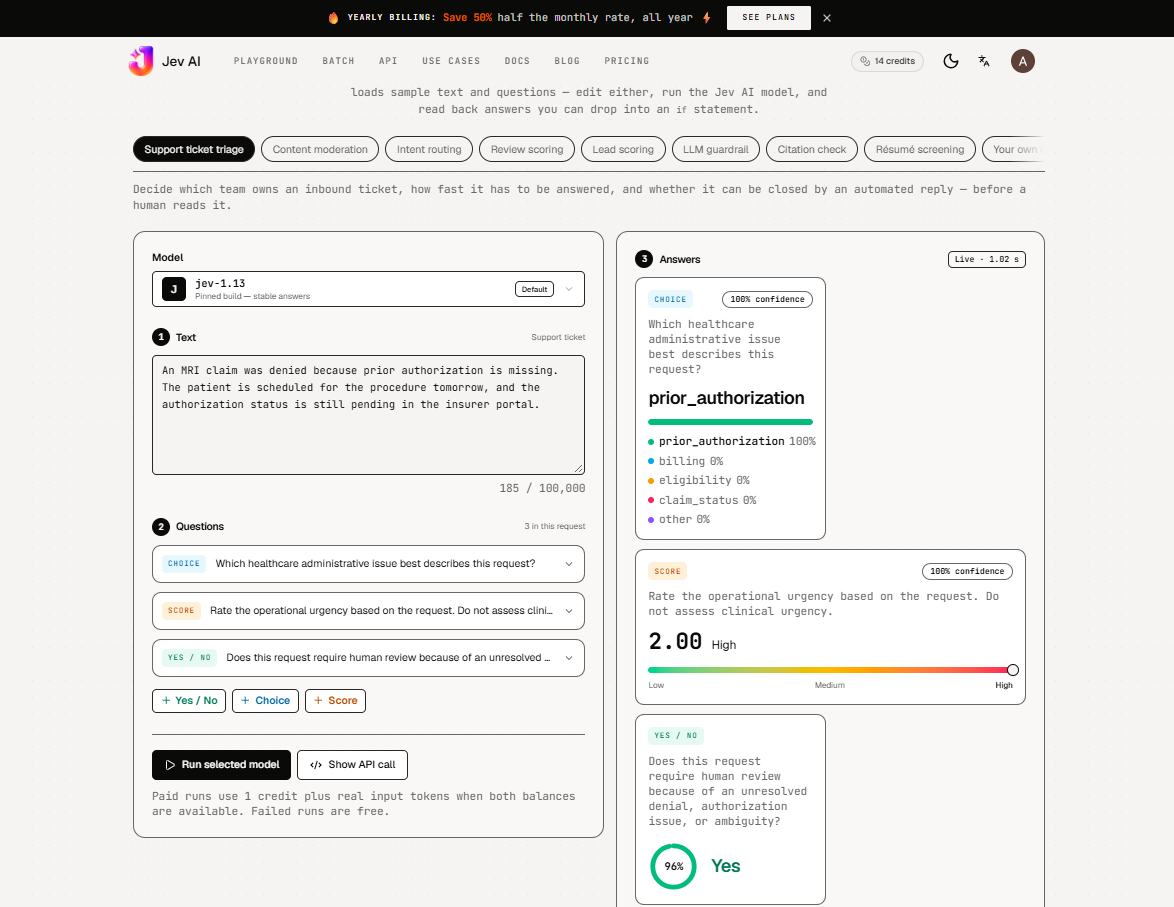

In [20]:
from IPython.display import Image, display

display(Image(filename=r"C:\Users\sathish.anantharaj\Documents\AV_Course\workshop\Codebasics_JEV_Usecases\JEV_Experiment.png"))